# Mathematical Transformations 

### 1.Log Transform 2. Reciprocal Transform 3.Power transform(sq/sqrt)

-> To convert into normal distribution

# 1.Log Transform

-> Take log of the data

### Generally used for right skewed data to make it normally distributed

## 2. Reciprocal transform

->  x' = 1/x

## 3. Square transform

In [1]:
import numpy as np 
import pandas as pd

import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_predict

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv('../train.csv', usecols=['Age', 'Fare', 'Survived'])

In [3]:
df.head()

ERROR! Session/line number was not unique in database. History logging moved to new session 65


,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [4]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [5]:
df['Age'].fillna(df['Age'].mean(), inplace=True)

/tmp/ipykernel_254211/1698716155.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


In [6]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [7]:
x = df.iloc[:, 1:]
y = df.iloc[:, 0]

In [8]:
x.head()

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.2, random_state=42)

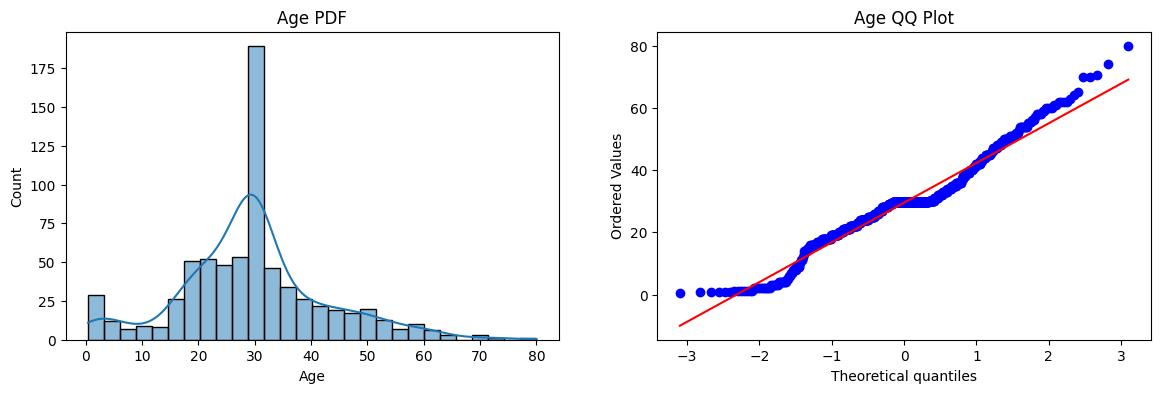

In [10]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train["Age"], kde = True)
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm', plot = plt)
plt.title("Age QQ Plot")
plt.show()

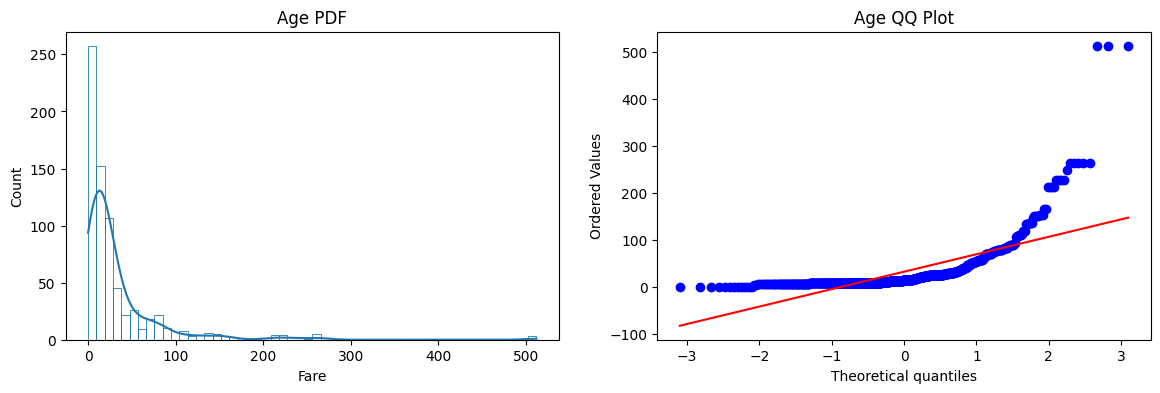

In [11]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train["Fare"], kde = True, fill = False)
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot = plt)
plt.title("Age QQ Plot")
plt.show()

In [12]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [13]:
clf.fit(X_train, Y_train)
clf2.fit( X_train, Y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf.predict(X_test)

print('Accuracy LR: ', accuracy_score(Y_test, y_pred))
print('Accuracy LR: ', accuracy_score(Y_test, y_pred1))


Accuracy LR:  0.6480446927374302
Accuracy LR:  0.6480446927374302


In [14]:
trf = FunctionTransformer(func=np.log1p)

### np.log1p --> log(1+x)

In [15]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [16]:
clf = LogisticRegression()
clf1 = DecisionTreeClassifier()

clf.fit(X_train_transformed, Y_train)
clf.fit(X_train_transformed, Y_train)

y_pred = clf.predict(X_test_transformed)
y_pred1 = clf.predict(X_test_transformed)
print('Accuracy LR: ', accuracy_score(Y_test, y_pred))
print('Accuracy LR: ', accuracy_score(Y_test, y_pred1))


Accuracy LR:  0.6815642458100558
Accuracy LR:  0.6815642458100558


Text(0.5, 1.0, 'Fare After log')

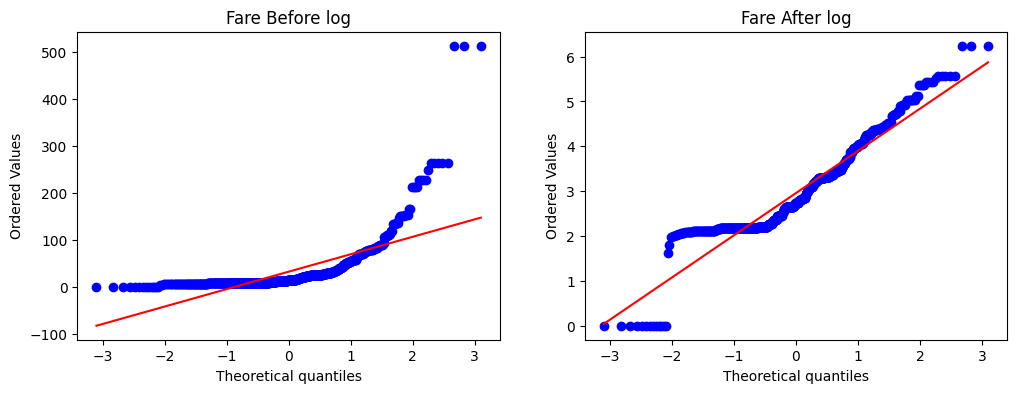

In [17]:
plt.figure(figsize=(12, 4))
plt.subplot(121)
stats.probplot(X_train['Fare'], dist = 'norm', plot = plt)
plt.title('Fare Before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist = 'norm', plot = plt)
plt.title('Fare After log')

Text(0.5, 1.0, 'Age After log')

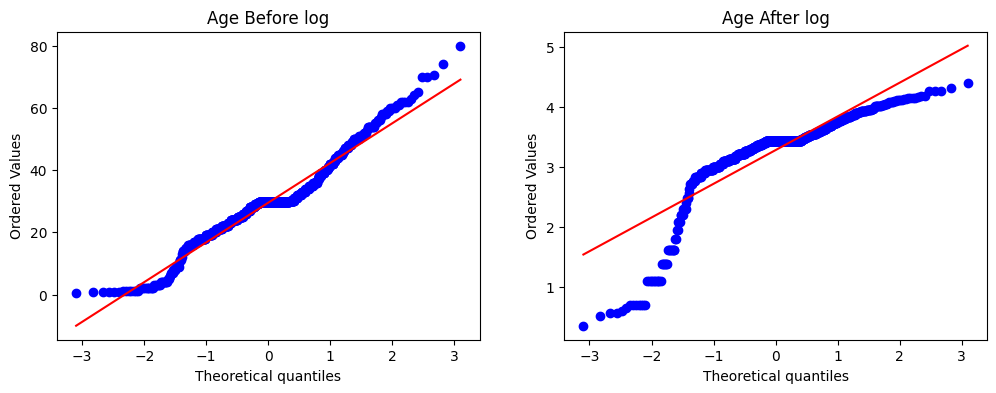

In [18]:
plt.figure(figsize=(12, 4))
plt.subplot(121)
stats.probplot(X_train['Age'], dist = 'norm', plot = plt)
plt.title('Age Before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist = 'norm', plot = plt)
plt.title('Age After log')

In [19]:
trf2  = ColumnTransformer([
    ('log', FunctionTransformer(np.log1p), ['Fare'])
], remainder='passthrough')
X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.fit_transform(X_test)


In [20]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [21]:
clf.fit(X_train_transformed2, Y_train)
clf2.fit(X_train_transformed2, Y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred1 = clf.predict(X_test_transformed2)
print('Accuracy LR: ', accuracy_score(Y_test, y_pred))
print('Accuracy LR: ', accuracy_score(Y_test, y_pred1))



Accuracy LR:  0.6703910614525139
Accuracy LR:  0.6703910614525139


In [26]:
import sklearn.model_selection

In [29]:
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(sklearn.model_selection.cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()

Accuracy 0.6712609238451936


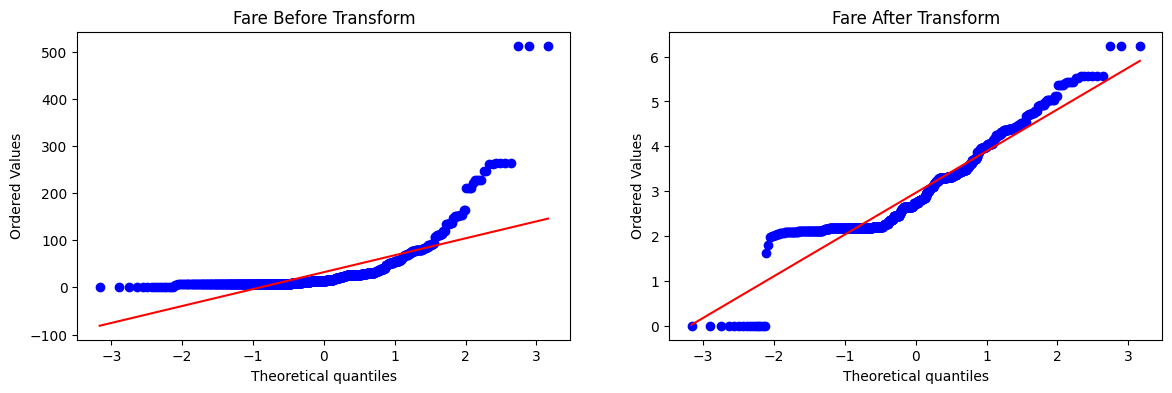

In [37]:
apply_transform(lambda x: np.log1p(x))